# 06-O3 — Sequential feature selection (Bogotá, O3 target)

Same LOYO-CV neural-net forward-selection methodology as the PM2.5 analysis (notebook
06), applied to O3. **Applies the lesson learned from PM2.5 from the start**: greedy SFS
structurally favors one clean predictor (raw day-of-year) over many individually-
-weaker-but-collectively-stronger ones (fire regions), so the "no-lag" run below
excludes calendar terms (`doy_sin`/`doy_cos`/`month_sin`/`month_cos`) as well as
`o3_lag1`, rather than re-discovering this the slow way.

No causal exclusions needed here (unlike PM10 for PM2.5) -- PM2.5, PMC and NO2 are all
independent, legitimate O3 predictors (aerosol-radiation feedback and NOx chemistry are
textbook mechanisms), not definitional subsets of O3.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "bogota"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "bogota" / "figures"

df = pd.read_parquet(DATA_DIR / "bogota_o3_master_dataset.parquet")
df = df.dropna(subset=['o3']).reset_index(drop=True)
df['year'] = df['date'].dt.year
print(df.shape)
df['year'].value_counts().sort_index()


(3285, 220)


year
2014    365
2015    365
2016    365
2017    365
2018    365
2019    365
2020    365
2021    365
2022    365
Name: count, dtype: int64

In [2]:
EXCLUDE = {'date', 'o3', 'year', 'pm10'}  # pm10 redundant with pm25+pmc decomposition
ALL_CANDIDATES = [c for c in df.columns if c not in EXCLUDE]
print(f"{len(ALL_CANDIDATES)} total candidate columns")

MIN_COVERAGE = 0.70
coverage = df[ALL_CANDIDATES].notna().mean()
CANDIDATES = coverage[coverage >= MIN_COVERAGE].index.tolist()
print(f"{len(CANDIDATES)} candidates meet >={MIN_COVERAGE:.0%} coverage")
dropped = sorted(set(ALL_CANDIDATES) - set(CANDIDATES))
print("Dropped for low coverage:", dropped)


216 total candidate columns
206 candidates meet >=70% coverage
Dropped for low coverage: ['hcho', 'hcho_lag1', 'hcho_lag2', 'hcho_lag3', 'rh_10m', 'so2', 'so2_lag1', 'so2_lag2', 'so2_lag3', 'temp_10m']


## LOYO cross-validated forward feature selection

In [3]:
from common.feature_selection import loyo_r2, sequential_forward_selection
# Parallelized across candidates within each SFS step (joblib, n_jobs=8) -- the earlier
# single-core inline version took 1-2+ hours per run and, when run concurrently with
# another such job, silently timed out without saving. See common/feature_selection.py.

In [4]:
print("=== SFS including o3_lag1 ===")
selected_with_lag, scores_with_lag = sequential_forward_selection(df, CANDIDATES, target='o3', n_jobs=8)


=== SFS including o3_lag1 ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


  + o3_lag1                             -> across-year R2 = 0.586


... (2 outputs left out)

  + wind_dir_sin                        -> across-year R2 = 0.693


  + hotspots_sector_NE                  -> across-year R2 = 0.718


  + wind_speed_era5                     -> across-year R2 = 0.731


  + day_of_week                         -> across-year R2 = 0.741


In [5]:
print("=== SFS excluding o3_lag1 AND calendar terms (physical substitutes only) ===")
CALENDAR_COLS = {'doy_sin', 'doy_cos', 'month_sin', 'month_cos'}
candidates_no_lag = [c for c in CANDIDATES if c not in CALENDAR_COLS | {'o3_lag1'}]
selected_no_lag, scores_no_lag = sequential_forward_selection(df, candidates_no_lag, target='o3', n_jobs=8)


=== SFS excluding o3_lag1 AND calendar terms (physical substitutes only) ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


  + photochemical_potential             -> across-year R2 = 0.259


... (19 outputs left out)

  + wind_speed_era5                     -> across-year R2 = 0.582


  + no_ratio                            -> across-year R2 = 0.637


  + w700                                -> across-year R2 = 0.647


  + radiation_mean                      -> across-year R2 = 0.658


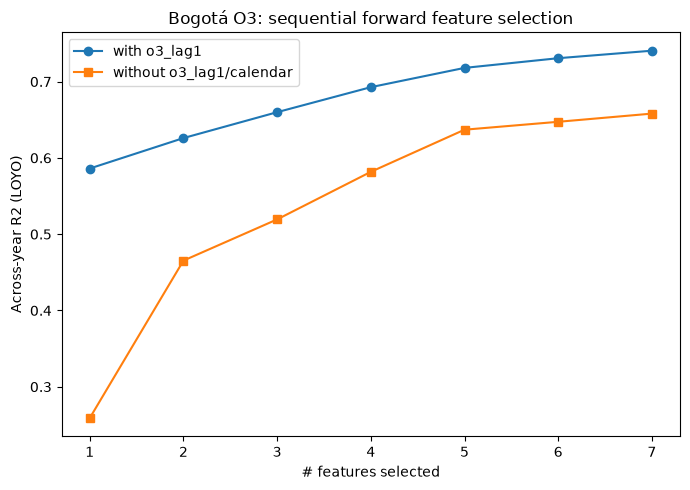

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(1, len(scores_with_lag) + 1), scores_with_lag, marker='o', label='with o3_lag1')
ax.plot(range(1, len(scores_no_lag) + 1), scores_no_lag, marker='s', label='without o3_lag1/calendar')
ax.set_xlabel('# features selected')
ax.set_ylabel('Across-year R2 (LOYO)')
ax.set_title('Bogotá O3: sequential forward feature selection')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'sfs_pareto_front_o3.png', dpi=150)
plt.show()


## Save selected feature sets for equation discovery

In [7]:
import json

result = {
    'selected_with_lag': selected_with_lag,
    'scores_with_lag': scores_with_lag,
    'selected_no_lag': selected_no_lag,
    'scores_no_lag': scores_no_lag,
}
out_path = DATA_DIR / "bogota_o3_feature_selection.json"
with open(out_path, 'w') as f:
    json.dump(result, f, indent=2)
print("Saved:", out_path)
print(result)


Saved: /path/to/project/Data/processed/colombia/bogota/bogota_o3_feature_selection.json
{'selected_with_lag': ['o3_lag1', 'photochemical_potential', 'fog_stagnation', 'wind_dir_sin', 'hotspots_sector_NE', 'wind_speed_era5', 'day_of_week'], 'scores_with_lag': [0.5860797045281503, 0.6259849117727005, 0.6599201247747941, 0.6927029124173428, 0.717982274331658, 0.7306866272699319, 0.7405160215060842], 'selected_no_lag': ['photochemical_potential', 'hotspots_sector_E_lag2', 'fog_stagnation', 'wind_speed_era5', 'no_ratio', 'w700', 'radiation_mean'], 'scores_no_lag': [0.2588734970395421, 0.46533728875338776, 0.5193751011449643, 0.5817154687210635, 0.6369581318485242, 0.6473234450004175, 0.6580563395752335]}
